<a href="https://colab.research.google.com/github/kxrrym03/Airline-Passenger-Satisfaction/blob/main/Airline_Passenger_Satisfaction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving test.csv to test.csv


In [ ]:
df = pd.read_csv('test.csv')
df.shape

(25976, 25)

In [ ]:
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied


In [ ]:
df.tail()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
25971,25971,78463,Male,disloyal Customer,34,Business travel,Business,526,3,3,...,4,3,2,4,4,5,4,0,0.0,neutral or dissatisfied
25972,25972,71167,Male,Loyal Customer,23,Business travel,Business,646,4,4,...,4,4,5,5,5,5,4,0,0.0,satisfied
25973,25973,37675,Female,Loyal Customer,17,Personal Travel,Eco,828,2,5,...,2,4,3,4,5,4,2,0,0.0,neutral or dissatisfied
25974,25974,90086,Male,Loyal Customer,14,Business travel,Business,1127,3,3,...,4,3,2,5,4,5,4,0,0.0,satisfied
25975,25975,34799,Female,Loyal Customer,42,Personal Travel,Eco,264,2,5,...,1,1,2,1,1,1,1,0,0.0,neutral or dissatisfied


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
id,0
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0


In [ ]:
# Fill missing values in 'Arrival Delay in Minutes' with its median
median_arrival_delay = df['Arrival Delay in Minutes'].median()
df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(median_arrival_delay)

# Verify that there are no more null values left
print("Null values after imputation:")
print(df.isnull().sum())


Null values after imputation:
Unnamed: 0                           0
id                                   0
Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                      

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Unnamed: 0,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.00000,25976.000000
mean,12987.500000,65005.657992,39.620958,1193.788459,2.724746,3.046812,2.756775,2.977094,3.215353,3.261665,3.449222,3.357753,3.385664,3.350169,3.633238,3.314175,3.649253,3.286226,14.30609,14.693756
std,7498.769632,37611.526647,15.135685,998.683999,1.335384,1.533371,1.412951,1.282133,1.331506,1.355536,1.320090,1.338299,1.282088,1.318862,1.176525,1.269332,1.180681,1.319330,37.42316,37.466787
min,0.000000,17.000000,7.000000,31.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.00000,0.000000
25%,6493.750000,32170.500000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.00000,0.000000
50%,12987.500000,65319.500000,40.000000,849.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.00000,0.000000
75%,19481.250000,97584.250000,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.00000,13.000000
max,25975.000000,129877.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1128.00000,1115.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   Gender                             25976 non-null  object 
 3   Customer Type                      25976 non-null  object 
 4   Age                                25976 non-null  int64  
 5   Type of Travel                     25976 non-null  object 
 6   Class                              25976 non-null  object 
 7   Flight Distance                    25976 non-null  int64  
 8   Inflight wifi service              25976 non-null  int64  
 9   Departure/Arrival time convenient  25976 non-null  int64  
 10  Ease of Online booking             25976 non-null  int64  
 11  Gate location                      25976 non-null  int

In [ ]:
df.dtypes

,0
Unnamed: 0,int64
id,int64
Gender,object
Customer Type,object
Age,int64
Type of Travel,object
Class,object
Flight Distance,int64
Inflight wifi service,int64
Departure/Arrival time convenient,int64


In [ ]:
df.columns

Index(['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

### 1. Overall Satisfaction Rate


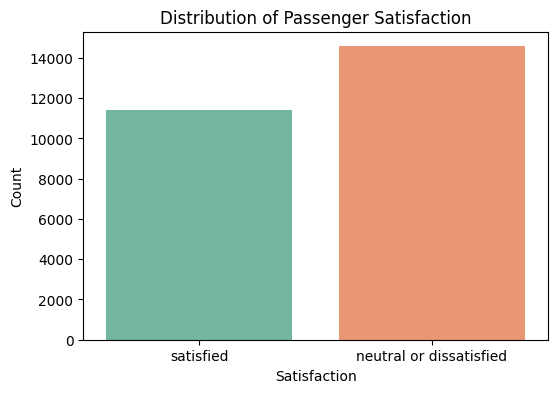

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='satisfaction', palette='Set2')
plt.title('Distribution of Passenger Satisfaction')
plt.xlabel('Satisfaction')
plt.ylabel('Count')
plt.show()


### 2. Satisfaction by Demographic & Travel Factors



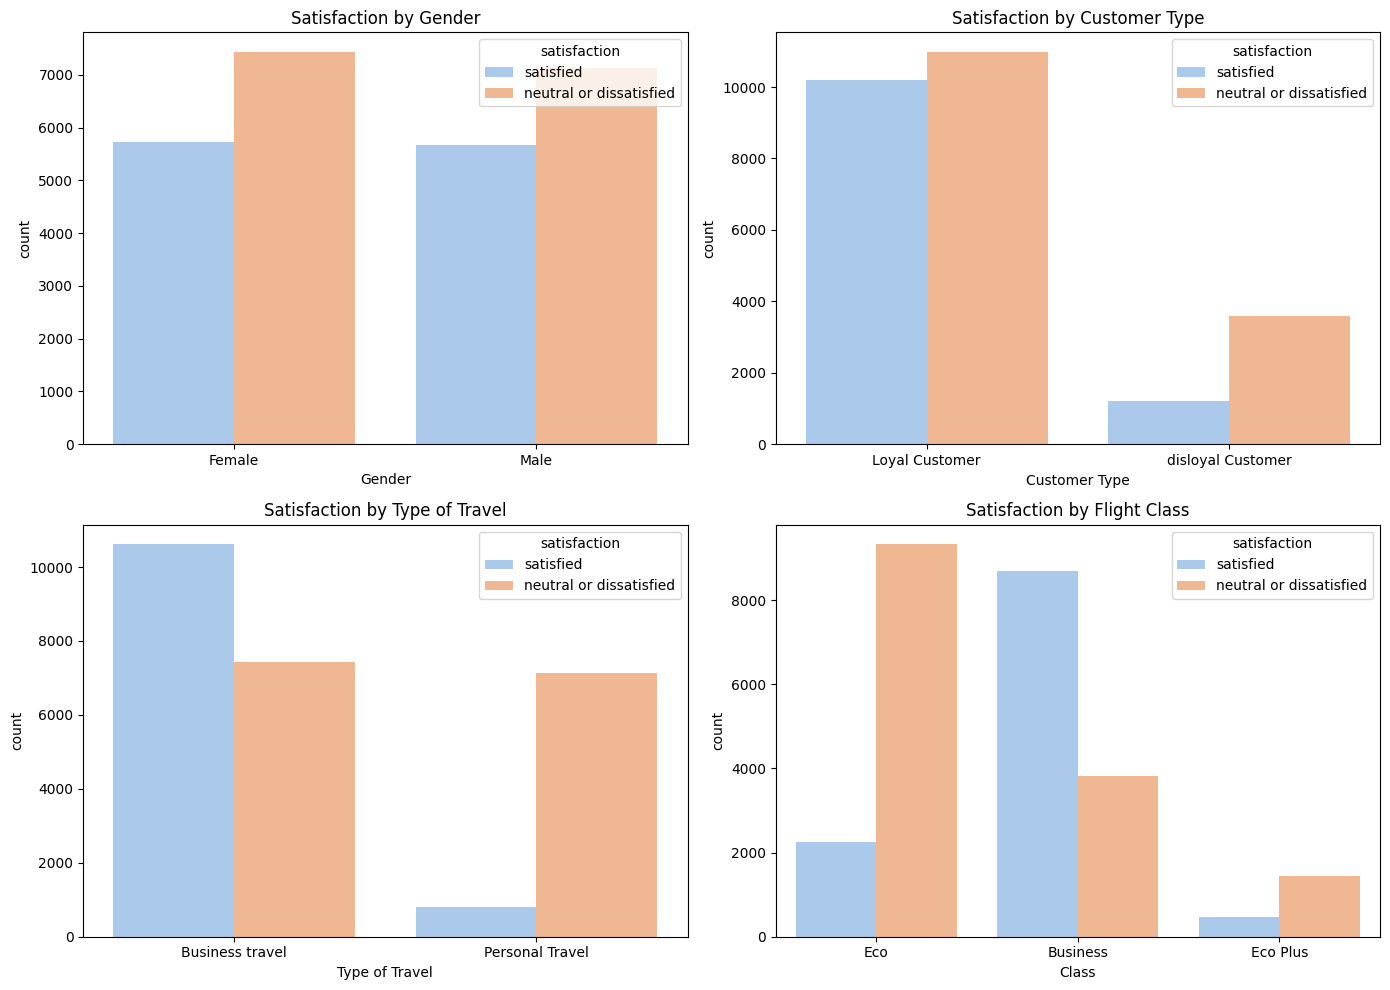

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='Gender', hue='satisfaction', ax=axes[0,0], palette='pastel')
axes[0,0].set_title('Satisfaction by Gender')

sns.countplot(data=df, x='Customer Type', hue='satisfaction', ax=axes[0,1], palette='pastel')
axes[0,1].set_title('Satisfaction by Customer Type')

sns.countplot(data=df, x='Type of Travel', hue='satisfaction', ax=axes[1,0], palette='pastel')
axes[1,0].set_title('Satisfaction by Type of Travel')

sns.countplot(data=df, x='Class', hue='satisfaction', ax=axes[1,1], palette='pastel')
axes[1,1].set_title('Satisfaction by Flight Class')

plt.tight_layout()
plt.show()

### 3. Age Distribution by Satisfaction


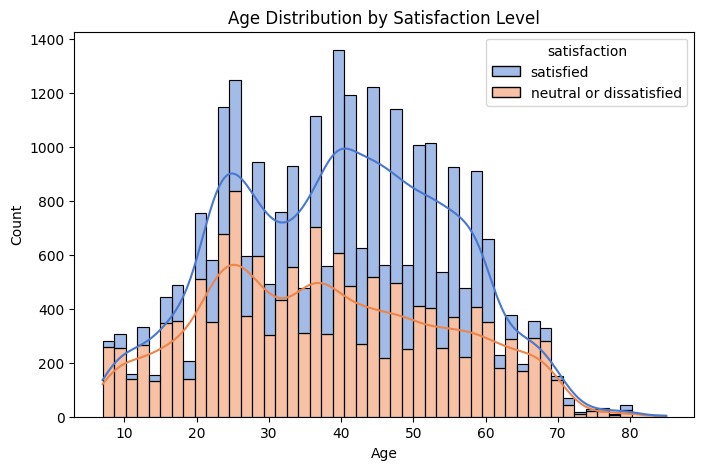

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='satisfaction', kde=True, multiple='stack', palette='muted')
plt.title('Age Distribution by Satisfaction Level')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

### 4. Correlation Heatmap


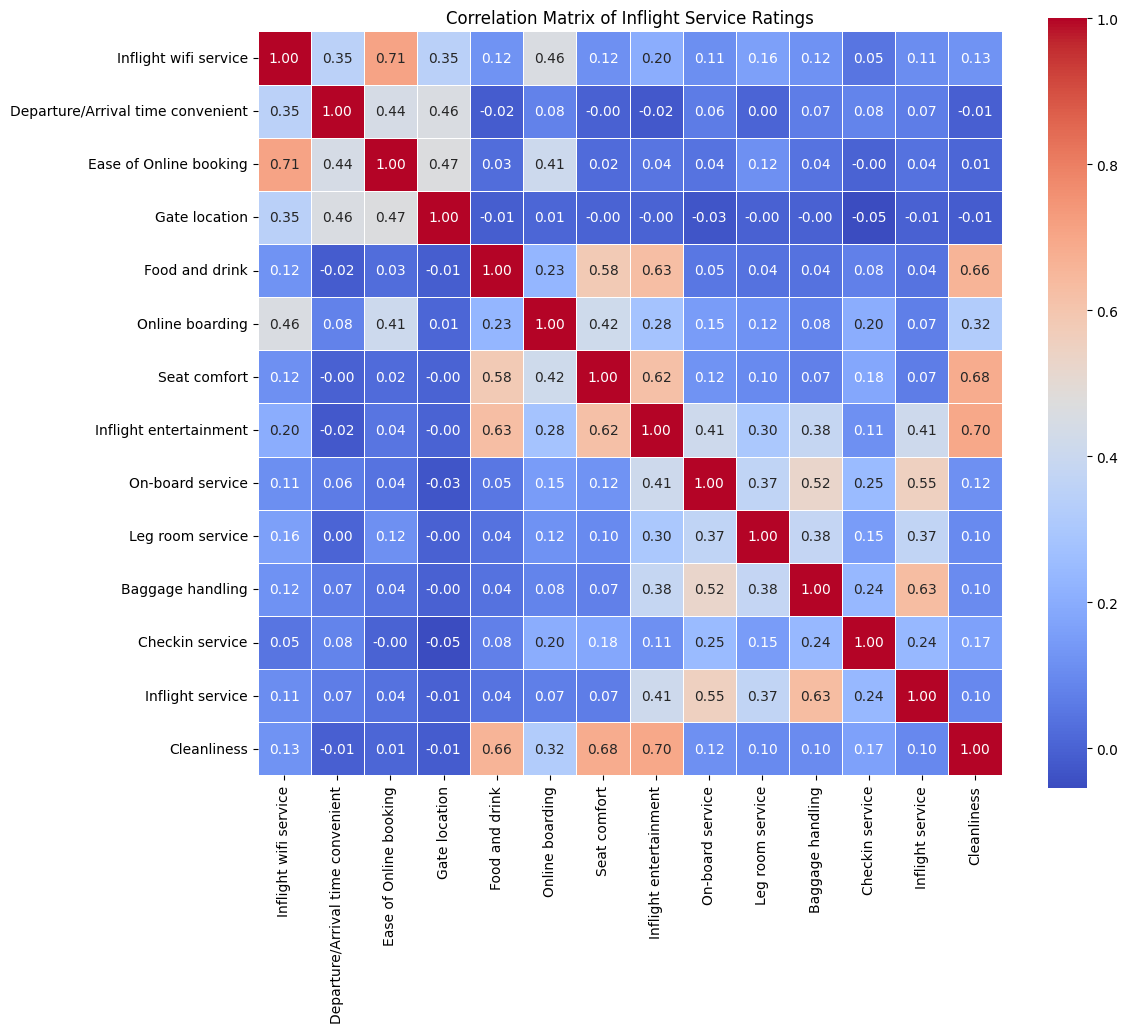

In [ ]:
# Select ratings features
ratings_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Inflight service', 'Cleanliness'
]

plt.figure(figsize=(12, 10))
correlation_matrix = df[ratings_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Inflight Service Ratings')
plt.show()

### 5. Flight Distance vs. Satisfaction


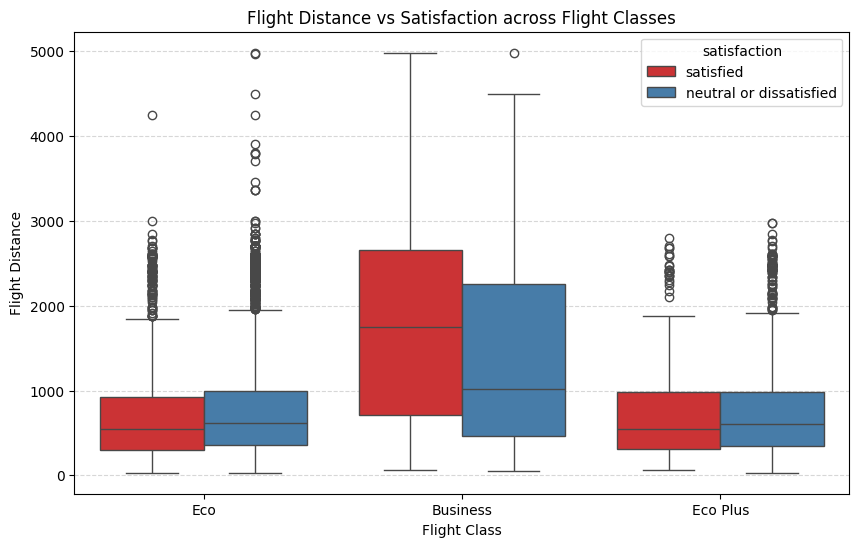

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Class', y='Flight Distance', hue='satisfaction', palette='Set1')
plt.title('Flight Distance vs Satisfaction across Flight Classes')
plt.xlabel('Flight Class')
plt.ylabel('Flight Distance')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### 6. Physical Comfort Services by Class


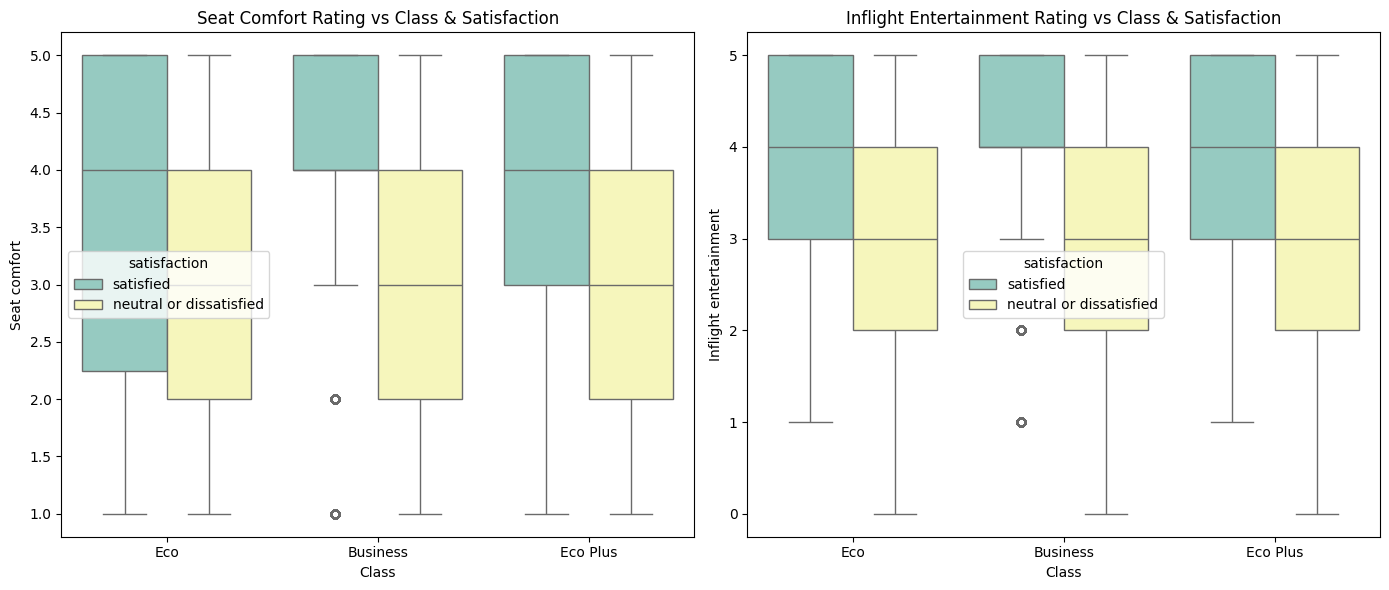

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=df, x='Class', y='Seat comfort', hue='satisfaction', ax=axes[0], palette='Set3')
axes[0].set_title('Seat Comfort Rating vs Class & Satisfaction')

sns.boxplot(data=df, x='Class', y='Inflight entertainment', hue='satisfaction', ax=axes[1], palette='Set3')
axes[1].set_title('Inflight Entertainment Rating vs Class & Satisfaction')

plt.tight_layout()
plt.show()

### Machine Learning

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Drop unnecessary identifier columns
ml_df = df.drop(columns=['Unnamed: 0', 'id'])

# Encode categorical variables
label_encoders = {}
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

for col in categorical_cols:
    le = LabelEncoder()
    ml_df[col] = le.fit_transform(ml_df[col])
    label_encoders[col] = le

# Split features and target
X = ml_df.drop(columns=['satisfaction'])
y = ml_df['satisfaction']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (20780, 22)
Testing set shape: (5196, 22)


In [ ]:
# Train a Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predict and evaluate
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoders['satisfaction'].classes_))

Model Accuracy: 0.9563

Classification Report:
                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.97      0.96      2915
              satisfied       0.96      0.94      0.95      2281

               accuracy                           0.96      5196
              macro avg       0.96      0.95      0.96      5196
           weighted avg       0.96      0.96      0.96      5196



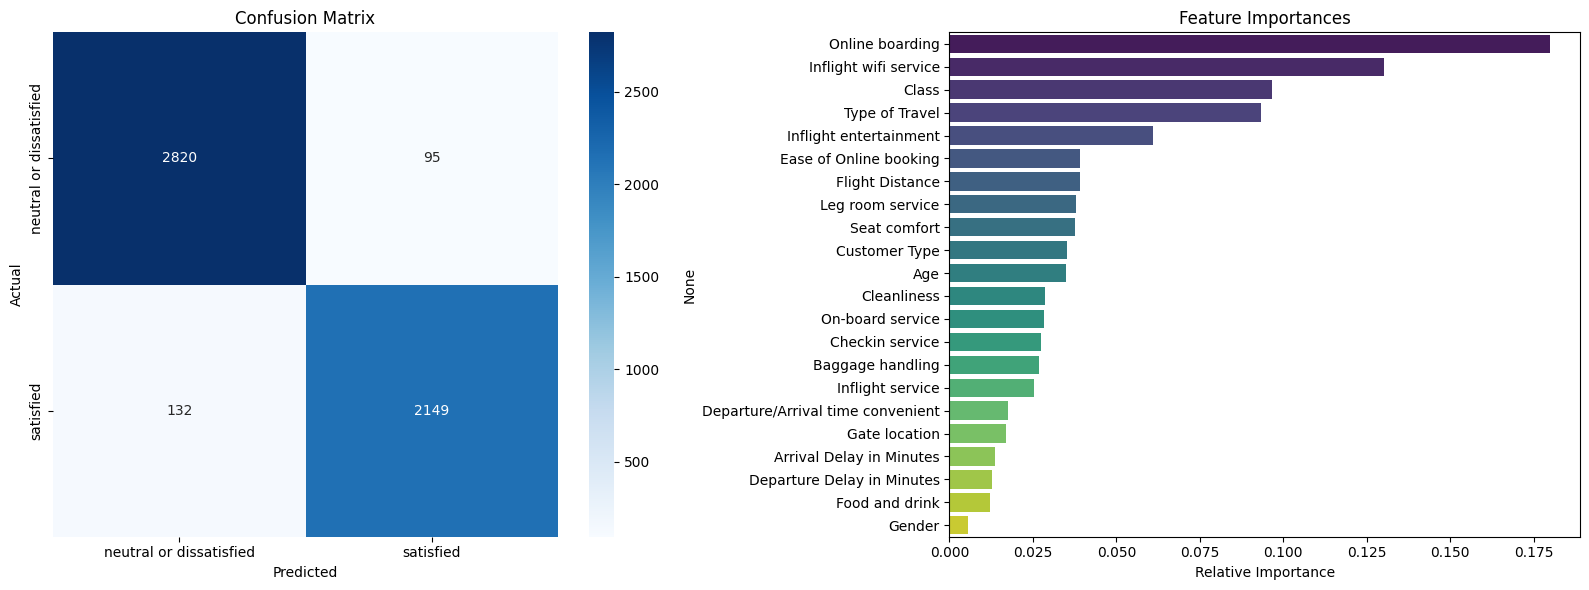

In [ ]:
# Plot Confusion Matrix and Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=label_encoders['satisfaction'].classes_,
            yticklabels=label_encoders['satisfaction'].classes_)
axes[0].set_title('Confusion Matrix')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Feature Importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = X.columns

sns.barplot(x=importances[indices], y=feature_names[indices], ax=axes[1], palette='viridis')
axes[1].set_title('Feature Importances')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

### Gradient Boosting

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Initialize and train the HistGradientBoostingClassifier
hgb_model = HistGradientBoostingClassifier(random_state=42)
hgb_model.fit(X_train, y_train)

# Predict and evaluate
y_pred_hgb = hgb_model.predict(X_test)
accuracy_hgb = accuracy_score(y_test, y_pred_hgb)

print(f"HistGradientBoosting Model Accuracy: {accuracy_hgb:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_hgb, target_names=label_encoders['satisfaction'].classes_))

HistGradientBoosting Model Accuracy: 0.9617

Classification Report:
                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.97      0.97      2915
              satisfied       0.97      0.95      0.96      2281

               accuracy                           0.96      5196
              macro avg       0.96      0.96      0.96      5196
           weighted avg       0.96      0.96      0.96      5196



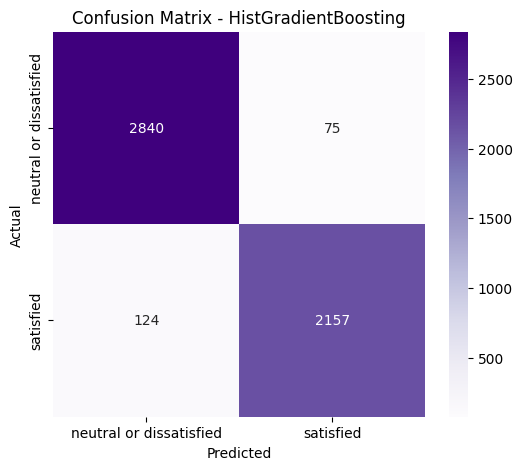

In [ ]:
# Plot Confusion Matrix for the Gradient Boosting Model
plt.figure(figsize=(6, 5))
cm_hgb = confusion_matrix(y_test, y_pred_hgb)
sns.heatmap(cm_hgb, annot=True, fmt='d', cmap='Purples',
            xticklabels=label_encoders['satisfaction'].classes_,
            yticklabels=label_encoders['satisfaction'].classes_)
plt.title('Confusion Matrix - HistGradientBoosting')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

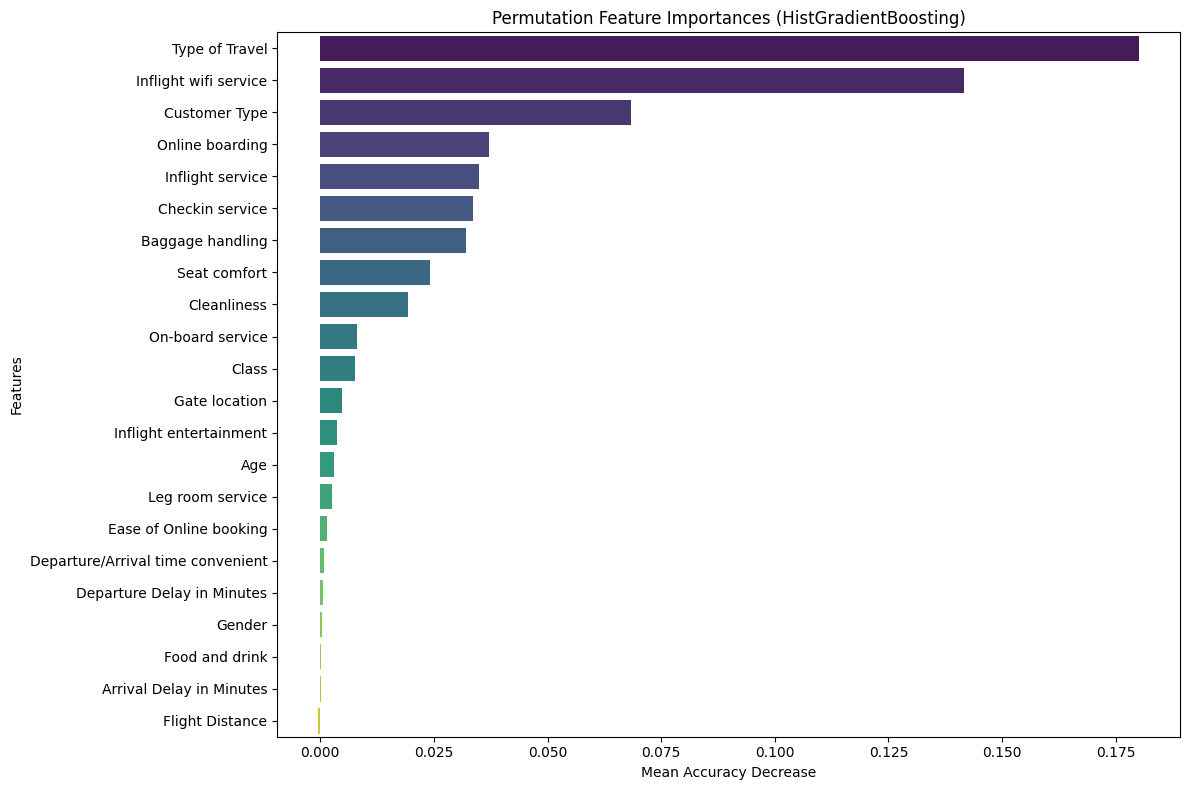

In [ ]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
result = permutation_importance(hgb_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

# Sort importances
sorted_importances_idx = result.importances_mean.argsort()[::-1]

# Plot
plt.figure(figsize=(12, 8))
sns.barplot(
    x=result.importances_mean[sorted_importances_idx],
    y=X_test.columns[sorted_importances_idx],
    palette='viridis'
)
plt.title('Permutation Feature Importances (HistGradientBoosting)')
plt.xlabel('Mean Accuracy Decrease')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### XGBoost Classifier

In [ ]:
from xgboost import XGBClassifier

# Initialize and train the XGBoost Classifier
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False)
xgb_model.fit(X_train, y_train)

# Predict and evaluate
y_pred_xgb = xgb_model.predict(X_test)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

print(f"XGBoost Model Accuracy: {accuracy_xgb:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_xgb, target_names=label_encoders['satisfaction'].classes_))

XGBoost Model Accuracy: 0.9592

Classification Report:
                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.97      0.96      2915
              satisfied       0.96      0.95      0.95      2281

               accuracy                           0.96      5196
              macro avg       0.96      0.96      0.96      5196
           weighted avg       0.96      0.96      0.96      5196



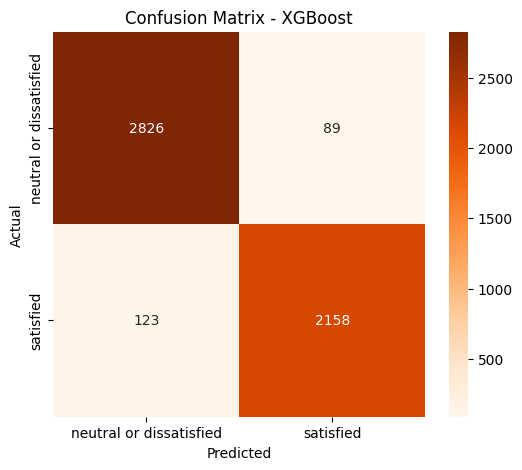

In [ ]:
# Plot Confusion Matrix for the XGBoost Model
plt.figure(figsize=(6, 5))
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=label_encoders['satisfaction'].classes_,
            yticklabels=label_encoders['satisfaction'].classes_)
plt.title('Confusion Matrix - XGBoost')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

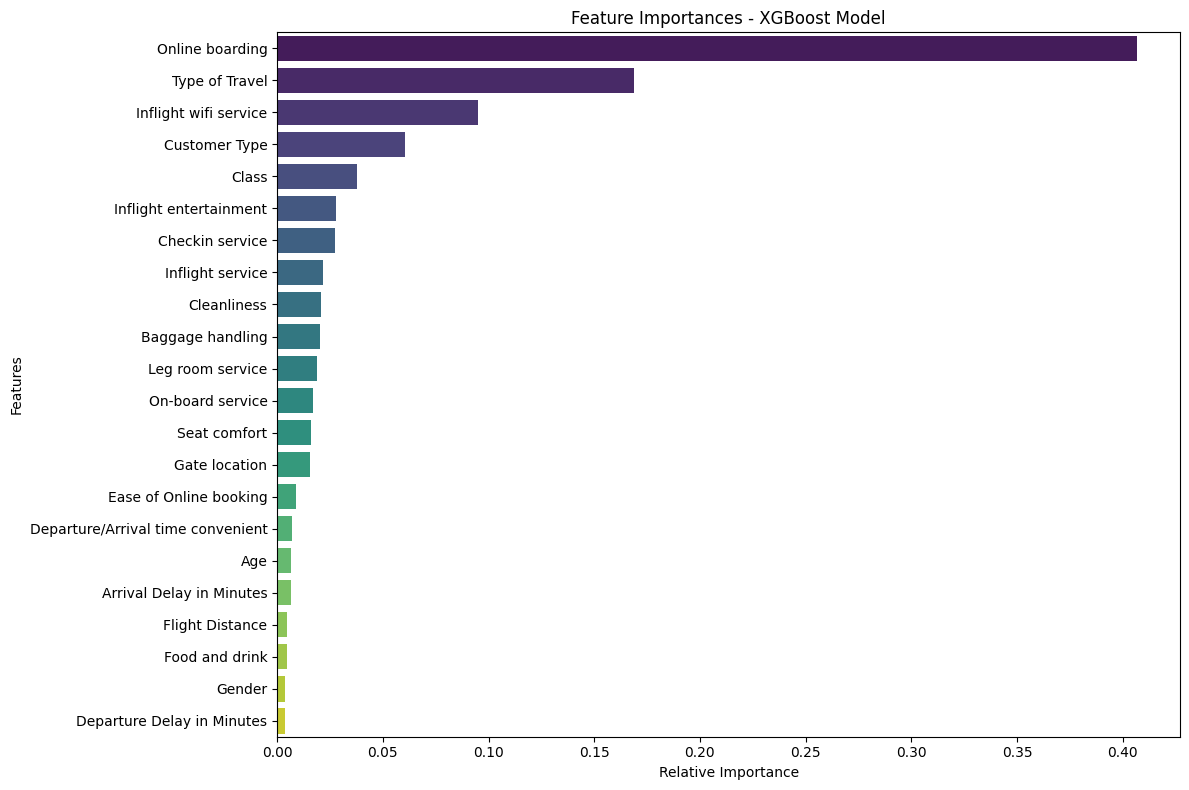

In [ ]:
# Get feature importances from the XGBoost model
xgb_importances = xgb_model.feature_importances_
xgb_indices = np.argsort(xgb_importances)[::-1]

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(
    x=xgb_importances[xgb_indices],
    y=X.columns[xgb_indices],
    palette='viridis'
)
plt.title('Feature Importances - XGBoost Model')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()